In [124]:
import argopy
# argopy.set_options(mode='research')
from argopy import DataFetcher

import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd
from shapely.geometry import Polygon, Point, box
from shapely.ops import unary_union
import numpy as np
from matplotlib.path import Path
import re
import time

In [2]:
argopy.set_options(
    src="erddap",
    mode="standard",
    ds="phy"
)
# Méditerranée
box = [
    -6, 37,          # longitude min/max
    30, 46,          # latitude min/max
    0, 6000,         # pression min/max
    "1993-01-01",    # date début
    "2026-10-01"     # date fin
]

In [3]:
f = argopy.DataFetcher().region(box)
f

<datafetcher.erddap>
⭐ Name: Ifremer erddap Argo data fetcher for a space/time region
🗺  Domain: [x=-6.00/37.00; y=30.00/46.00; z=0.0/6000.0; t=1993-01-01/2026-10-01]
🔗 API: https://erddap.ifremer.fr/erddap
🏊 User mode: standard
🟡+🔵 Dataset: phy
🌥  Performances: cache=False, parallel=False

In [6]:
import argopy

argopy.set_options(
    src="erddap",
    mode="standard"
)

from argopy import IndexFetcher

idx = IndexFetcher(src="erddap").region([
    -6, 37,          # longitude min/max
    30, 46,          # latitude min/max
    "1993-01-01",    # date début
    "2026-10-01"     # date fin
])

print(idx)

<indexfetcher.erddap>
Name: Ifremer erddap Argo Index fetcher for a space/time region
API: https://erddap.ifremer.fr/erddap
Domain: [x=-6.00/37.00; y=30.00/46.00; t=1993-01-01/2026-10-01]
Backend: erddap
User mode: standard
Dataset: phy
Loaded: False


In [7]:
df = idx.to_dataframe()

print(df.shape)
print(df.columns)

(119163, 11)
Index(['file', 'date', 'longitude', 'latitude', 'ocean', 'profiler_code',
       'institution_code', 'date_update', 'wmo', 'institution', 'profiler'],
      dtype='object')


In [34]:
df_med = df[(
    (df["longitude"] >= -6) &
    (df["longitude"] <= 37) &
    (df["latitude"] >= 30) &
    (df["latitude"] <= 46) &
    ~(
        (df["longitude"] > 27) &
        (df["latitude"] > 40)
    ) &
    ~(
        (df["longitude"] < 0) &
        (df["latitude"] > 42)
)
)].copy()

In [35]:
print("Nombre de bouées :", df_med["wmo"].nunique())

Nombre de bouées : 566


In [36]:
df_med["wmo"] = df_med["file"].str.extract(r"(\d{7})")

In [37]:
print(df_med["wmo"].nunique())

566


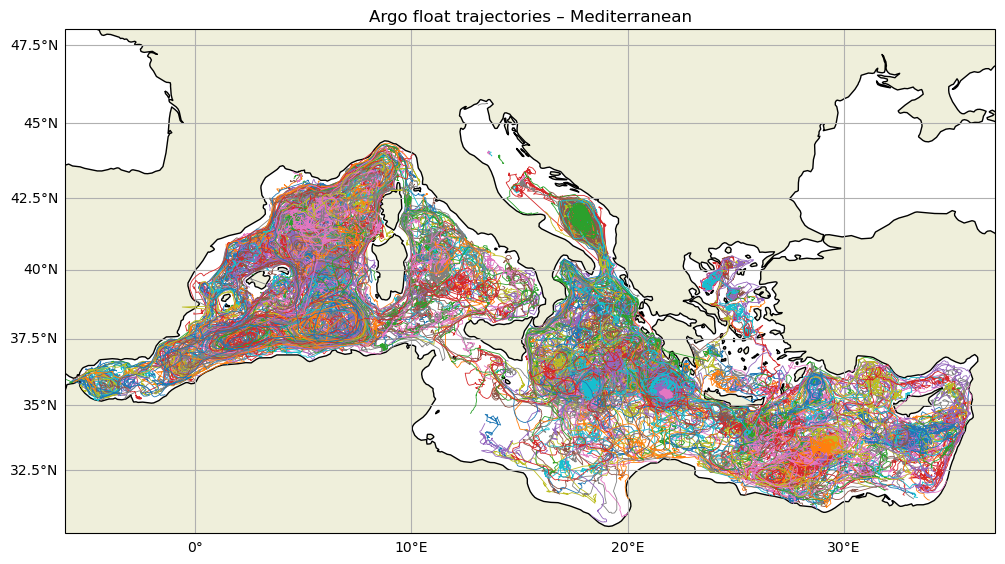

In [38]:
fig = plt.figure(figsize=(12, 8))

ax = plt.axes(projection=ccrs.Mercator())

ax.set_extent([-6, 37, 30, 46])

ax.coastlines(resolution="50m")
ax.add_feature(cfeature.LAND)
gl = ax.gridlines(draw_labels=True)
gl.top_labels = gl.right_labels = False
for wmo, d in df_med.groupby("wmo"):

    d = d.sort_values("date")

    ax.plot(
        d["longitude"],
        d["latitude"],
        linewidth=0.6,
        transform=ccrs.PlateCarree()
    )

ax.set_title("Argo float trajectories – Mediterranean")

plt.show()

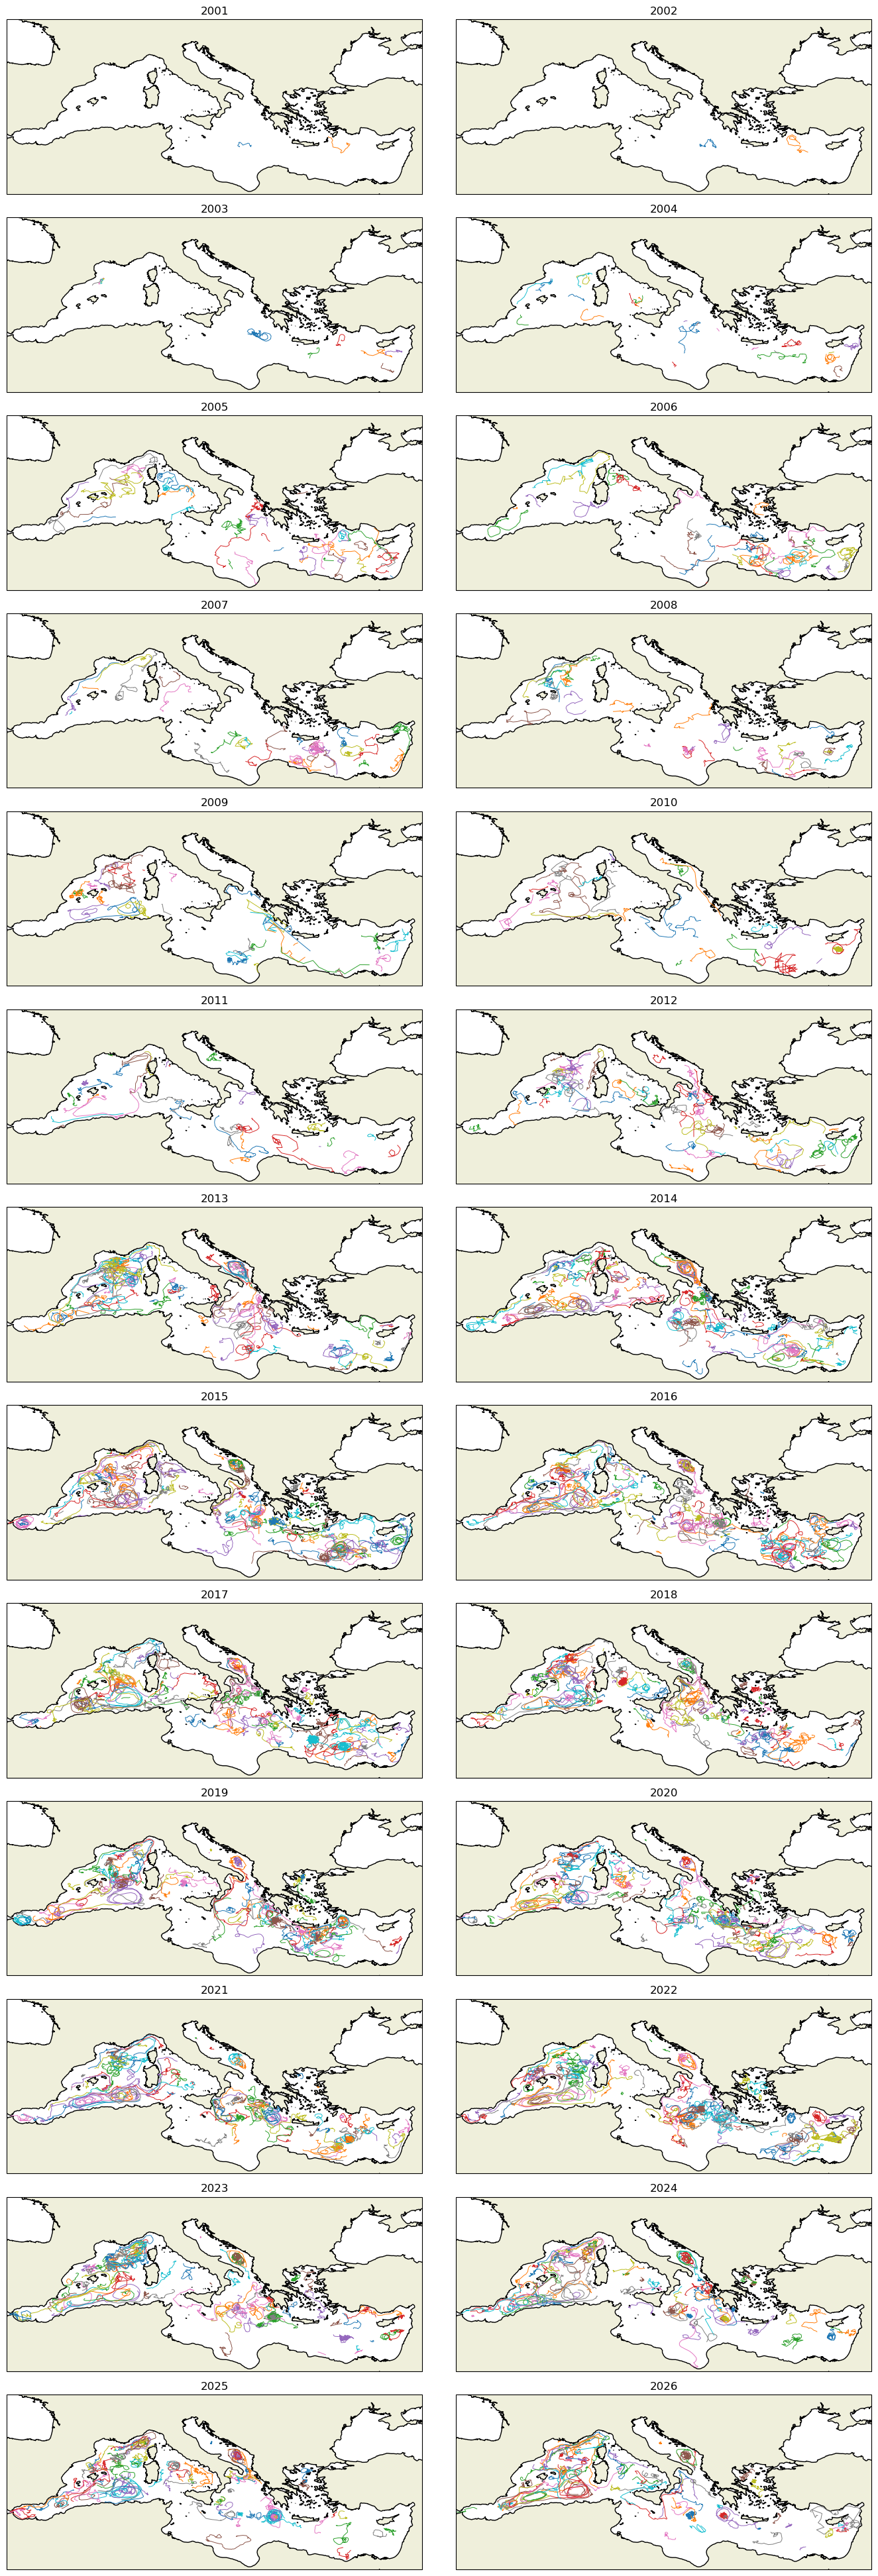

In [42]:
# S'assurer que date est bien au format datetime
df_med["date"] = pd.to_datetime(df_med["date"])

# Années disponibles
years = sorted(df_med["date"].dt.year.unique())

# Nombre de lignes pour 2 colonnes
ncols = 2
nrows = (len(years) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(14, 3 * nrows),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# Transformer axes en tableau 1D
axes = axes.flatten()

for ax, year in zip(axes, years):

    # Données uniquement de cette année
    df_year = df_med[
        df_med["date"].dt.year == year
    ].copy()

    # Carte
    ax.set_extent([-6, 37, 30, 46])

    ax.coastlines(resolution="10m")
    ax.add_feature(cfeature.LAND)

    # Trajectoire de chaque flotteur
    for wmo, d in df_year.groupby("wmo"):

        d = d.sort_values("date")

        ax.plot(
            d["longitude"],
            d["latitude"],
            linewidth=0.7,
            transform=ccrs.PlateCarree()
        )

    ax.set_title(str(year))

# Supprimer les axes inutilisés
for ax in axes[len(years):]:
    ax.remove()

plt.tight_layout()
plt.show()

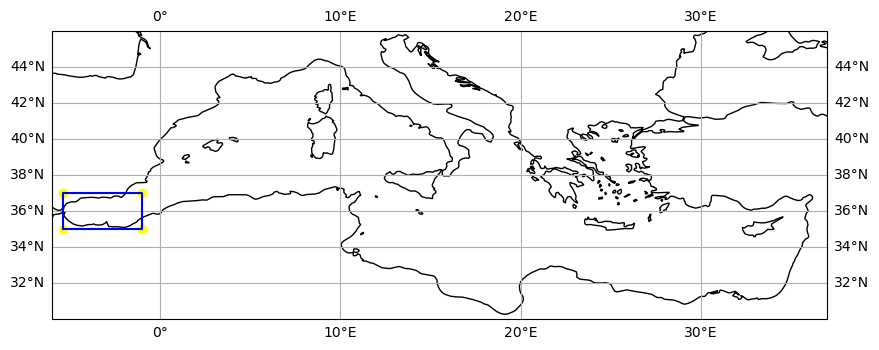

In [58]:
# Alboran
poly_coords = [(-5.4, 35),
               (-1, 35),
               (-1, 37),
               (-5.4, 37),
              ]
polygon = Polygon(poly_coords)
def point_in_polygon(lon, lat):
    return polygon.contains(Point(lon, lat))

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, dms=False, x_inline=False, y_inline=False)
ax.add_feature(cfeature.COASTLINE)
ax.set_extent([-6, 37, 30, 46], crs=ccrs.PlateCarree())
for lon, lat in poly_coords:
    plt.scatter(lon, lat, color='yellow', transform=ccrs.PlateCarree())
x, y = polygon.exterior.xy
plt.plot(x, y, transform=ccrs.PlateCarree(), color='blue')
plt.show()

In [ ]:
# Garde tous les profils si à un moment, la bouée est passée dans la box
inside = [
    polygon.contains(Point(lon, lat))
    for lon, lat in zip(df_med["longitude"], df_med["latitude"])
]

wmo_alb = df_med.loc[inside, "wmo"].unique()

df_alb = df_med[df_med["wmo"].isin(wmo_alb)].copy()

print(f"Nombre de bouées : {df_alb['wmo'].nunique()}")
print(f"Nombre de profils : {len(df_alb)}")

Nombre de bouées : 52
Nombre de profils : 10566


In [64]:
# Garde seulement les profils dans la box
inside = [
    polygon.covers(Point(lon, lat))
    for lon, lat in zip(df_med["longitude"], df_med["latitude"])
]

df_alb = df_med.loc[inside].copy()
print(f"Nombre de bouées : {df_alb['wmo'].nunique()}")
print(f"Nombre de profils : {len(df_alb)}")

Nombre de bouées : 52
Nombre de profils : 3381


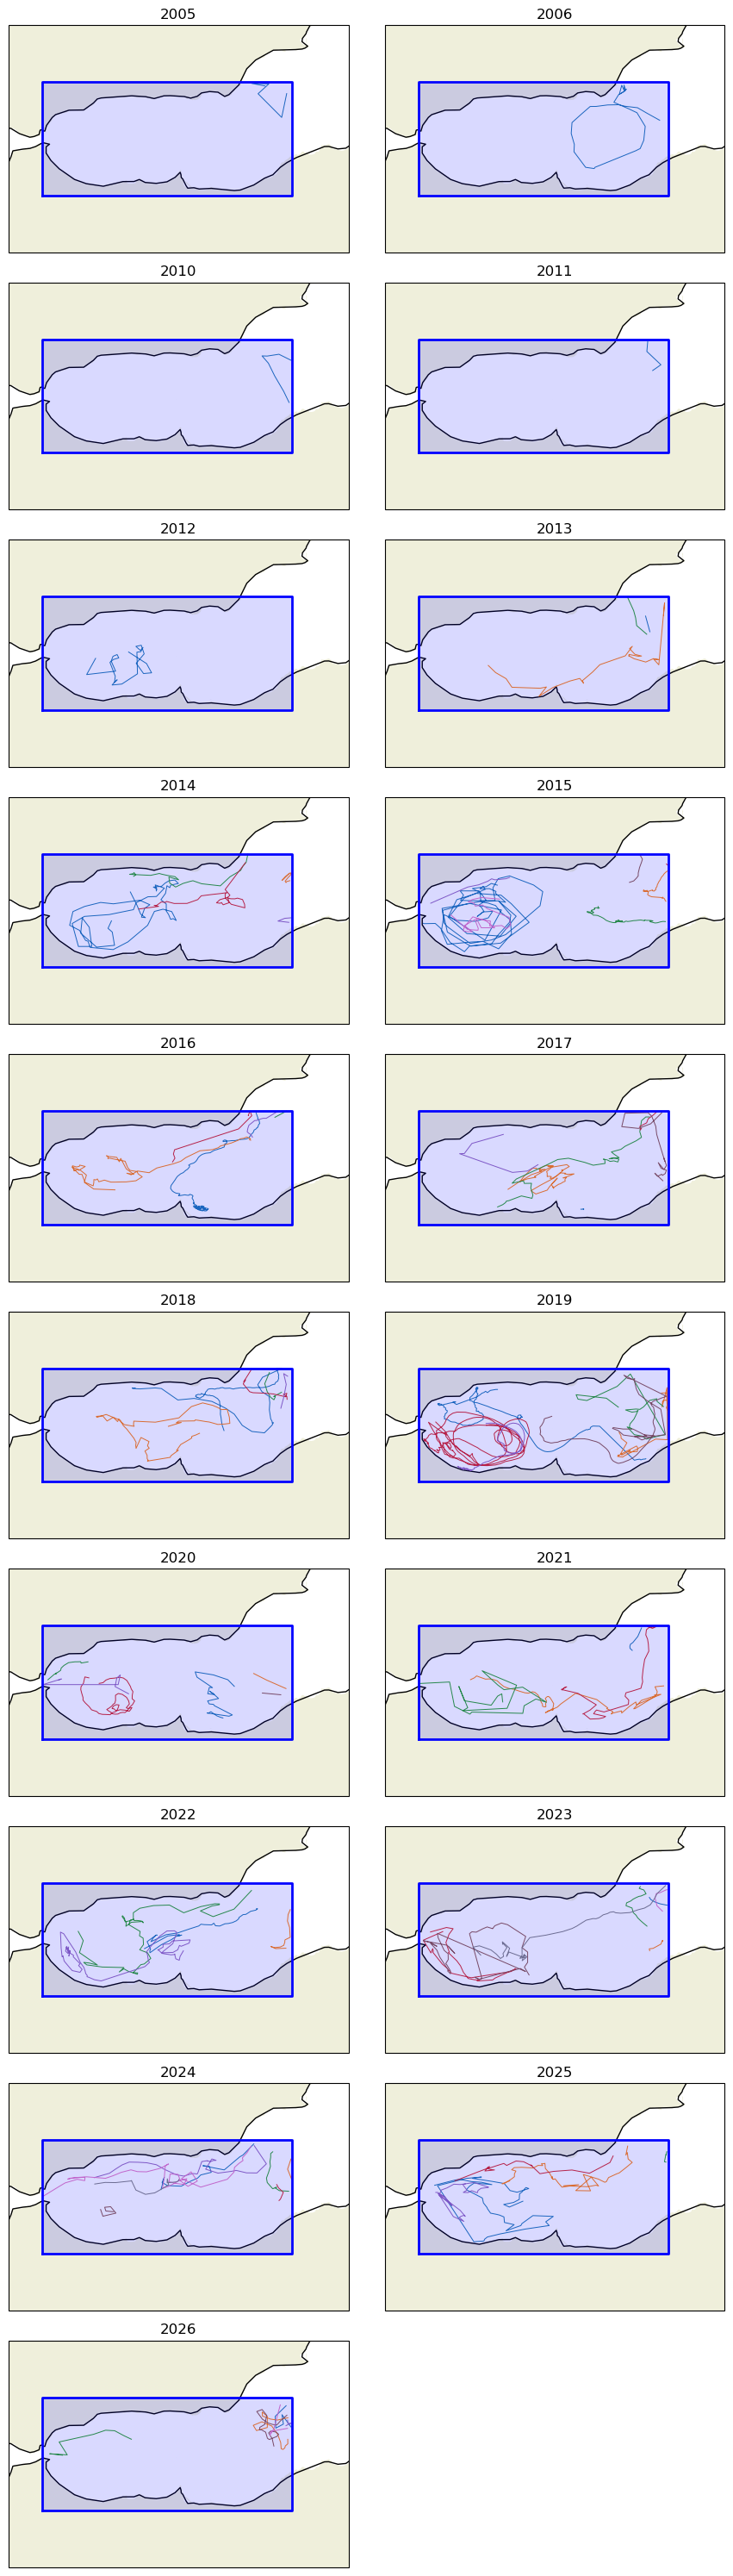

In [68]:
# S'assurer que date est bien au format datetime
df_alb["date"] = pd.to_datetime(df_alb["date"])

# Années disponibles
years = sorted(df_alb["date"].dt.year.unique())

# Nombre de lignes pour 2 colonnes
ncols = 2
nrows = (len(years) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(9, 3 * nrows),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

axes = axes.flatten()

for ax, year in zip(axes, years):

    # Données uniquement de cette année
    df_year = df_alb[
        df_alb["date"].dt.year == year
    ].copy()

    # Carte
    ax.set_extent([-6, 0, 34, 38])
    ax.coastlines(resolution="50m")
    ax.add_feature(cfeature.LAND)

    # ---------------------------------------------------------
    # POLYGONE ALBORAN
    # ---------------------------------------------------------
    x, y = polygon.exterior.xy

    ax.plot(
        x,
        y,
        color="blue",
        linewidth=2,
        transform=ccrs.PlateCarree(),
        zorder=5
    )

    # éventuellement remplir légèrement le polygone
    ax.fill(
        x,
        y,
        color="blue",
        alpha=0.15,
        transform=ccrs.PlateCarree(),
        zorder=4
    )

    # ---------------------------------------------------------
    # TRAJECTOIRES
    # ---------------------------------------------------------
    for wmo, d in df_year.groupby("wmo"):

        d = d.sort_values("date")

        ax.plot(
            d["longitude"],
            d["latitude"],
            linewidth=0.7,
            transform=ccrs.PlateCarree(),
            zorder=3
        )

    ax.set_title(str(year))

# Supprimer les axes inutilisés
for ax in axes[len(years):]:
    ax.remove()

plt.tight_layout()
plt.show()

In [82]:
mask = np.load(
    '../../../Med_Global_EKE/results/masks/2mask_IERAISO_MED.npy',
    allow_pickle=True
)
ekem = xr.open_dataset('../../../Med_Global_EKE/processed_data/MED/ALL_SAT/NEKE_ALL_SAT_MED_C3S_vDT2021_19930101_20230607.nc')
meanekem = ekem.mean(dim='time', skipna=False)

lon = meanekem['lon'].values
lat = meanekem['lat'].values

# Résolution de la grille
dlon = np.abs(np.diff(lon).mean())
dlat = np.abs(np.diff(lat).mean())

print("Résolution lon :", dlon)
print("Résolution lat :", dlat)

# Demi-résolution
half_dlon = dlon / 2
half_dlat = dlat / 2

# Liste des cellules appartenant au masque
cells = []

for j, lat0 in enumerate(lat):
    for i, lon0 in enumerate(lon):

        if mask[j, i]:

            cell = box(
                lon0 - half_dlon,
                lat0 - half_dlat,
                lon0 + half_dlon,
                lat0 + half_dlat
            )

            cells.append(cell)

# Fusionner toutes les cellules
polygon_iera = unary_union(cells)

print(type(polygon_iera))
print("Surface :", polygon_iera.area)

Résolution lon : 0.125
Résolution lat : 0.125
<class 'shapely.geometry.polygon.Polygon'>
Surface : 2.421875


In [85]:
polygon_iera_buffer = polygon_iera.buffer(0.5)

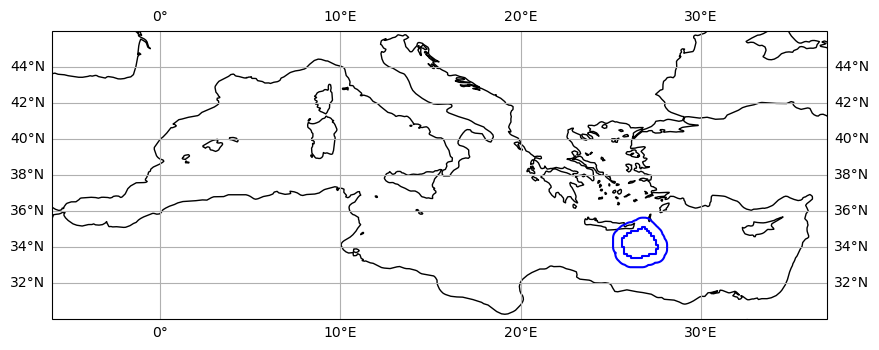

In [87]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.gridlines(draw_labels=True, dms=False, x_inline=False, y_inline=False)
ax.add_feature(cfeature.COASTLINE)
ax.set_extent([-6, 37, 30, 46], crs=ccrs.PlateCarree())
x, y = polygon_iera_buffer.exterior.xy
plt.plot(x, y, transform=ccrs.PlateCarree(), color='blue')
x, y = polygon_iera.exterior.xy
plt.plot(x, y, transform=ccrs.PlateCarree(), color='blue')
plt.show()

In [88]:
inside = [
    polygon_iera_buffer.covers(Point(lon, lat))
    for lon, lat in zip(df_med["longitude"], df_med["latitude"])
]

df_iera = df_med.loc[inside].copy()

print(f"Nombre de bouées : {df_iera['wmo'].nunique()}")
print(f"Nombre de profils : {len(df_iera)}")

Nombre de bouées : 89
Nombre de profils : 4133


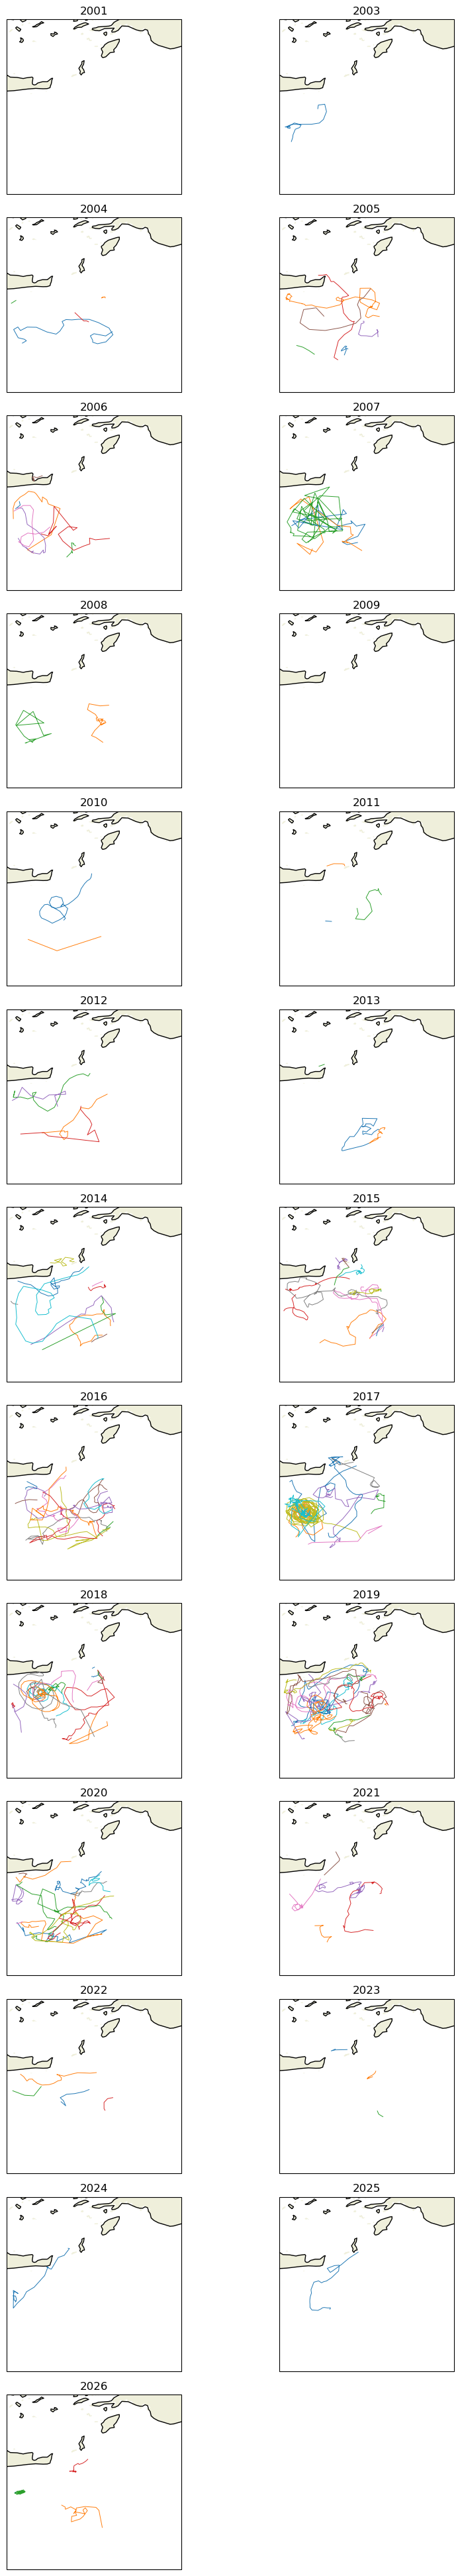

In [90]:
# S'assurer que date est bien au format datetime
df_iera["date"] = pd.to_datetime(df_iera["date"])

# Années disponibles
years = sorted(df_iera["date"].dt.year.unique())

# Nombre de lignes pour 2 colonnes
ncols = 2
nrows = (len(years) + ncols - 1) // ncols

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(9, 3 * nrows),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

axes = axes.flatten()

for ax, year in zip(axes, years):

    # Données uniquement de cette année
    df_year = df_iera[
        df_iera["date"].dt.year == year
    ].copy()

    # Carte
    ax.set_extent([25, 30, 32, 37])
    ax.coastlines(resolution="50m")
    ax.add_feature(cfeature.LAND)

    # ---------------------------------------------------------
    # POLYGONE ALBORAN
    # ---------------------------------------------------------
    x, y = polygon.exterior.xy

    ax.plot(
        x,
        y,
        color="blue",
        linewidth=2,
        transform=ccrs.PlateCarree(),
        zorder=5
    )

    # éventuellement remplir légèrement le polygone
    ax.fill(
        x,
        y,
        color="blue",
        alpha=0.15,
        transform=ccrs.PlateCarree(),
        zorder=4
    )

    # ---------------------------------------------------------
    # TRAJECTOIRES
    # ---------------------------------------------------------
    for wmo, d in df_year.groupby("wmo"):

        d = d.sort_values("date")

        ax.plot(
            d["longitude"],
            d["latitude"],
            linewidth=0.7,
            transform=ccrs.PlateCarree(),
            zorder=3
        )

    ax.set_title(str(year))

# Supprimer les axes inutilisés
for ax in axes[len(years):]:
    ax.remove()

plt.tight_layout()
plt.show()

In [145]:
profiles = (
    df_iera[["wmo", "file"]]
    .drop_duplicates()
    .copy()
)

profiles["cyc"] = (
    profiles["file"]
    .str.extract(r"_(\d+)(?:D)?\.nc$")[0]
    .astype(int)
)

print(f"Profils sélectionnés : {len(profiles)}")
print(f"Flotteurs : {profiles['wmo'].nunique()}")

Profils sélectionnés : 4133
Flotteurs : 89


In [ ]:
#avoir les donnees brutes
datasets = []

for wmo, group in profiles.groupby("wmo"):

    cycles = group["cyc"].unique()

    print(
        f"WMO {wmo} : "
        f"{len(cycles)} profils demandés"
    )

    try:

        af = argopy.ArgoFloat(int(wmo))

        ds = af.open_dataset("prof")

        # Garder uniquement les cycles sélectionnés
        mask = np.isin(
            ds["CYCLE_NUMBER"].values,
            cycles
        )

        ds = ds.isel(N_PROF=mask)

        print(
            f"  → {ds.sizes['N_PROF']} profils récupérés"
        )

        if ds.sizes["N_PROF"] > 0:
            datasets.append(ds)

    except Exception as e:

        print(
            f"  → ERREUR : "
            f"{type(e).__name__}: {e}"
        )

        continue

WMO 1900589 : 3 profils demandés
  → 3 profils récupérés
WMO 1900590 : 17 profils demandés
  → 17 profils récupérés
WMO 1900591 : 20 profils demandés
  → 21 profils récupérés
WMO 1900603 : 16 profils demandés
  → 17 profils récupérés
WMO 1900604 : 42 profils demandés
  → 42 profils récupérés
WMO 1900606 : 1 profils demandés
  → 1 profils récupérés
WMO 1900832 : 27 profils demandés
  → 27 profils récupérés
WMO 1900945 : 33 profils demandés
  → 33 profils récupérés
WMO 1900949 : 1 profils demandés
  → 1 profils récupérés
WMO 1900951 : 33 profils demandés
  → 33 profils récupérés
WMO 1900953 : 32 profils demandés
  → 32 profils récupérés
WMO 1900955 : 16 profils demandés
  → 16 profils récupérés
WMO 1901518 : 67 profils demandés
  → 67 profils récupérés
WMO 2902635 : 17 profils demandés
  → 17 profils récupérés
WMO 2904085 : 4 profils demandés
  → 4 profils récupérés
WMO 3901853 : 28 profils demandés
  → 28 profils récupérés
WMO 3901977 : 89 profils demandés
  → 89 profils récupérés
WMO 3

In [153]:
argopy.set_options(
    src="erddap",
    mode="standard"
)
argo = DataFetcher(src="erddap", mode="standard")

In [154]:
datasets = {}

for wmo, group in profiles.groupby("wmo"):

    cycles = group["cyc"].unique().tolist()

    print(f"WMO {wmo} : {len(cycles)} profils")

    try:
        ds = (
            DataFetcher(src="erddap", mode="standard")
            .profile(int(wmo), cycles)
            .load()
            .data
        )

        datasets[int(wmo)] = ds

        print(f"  → {ds.sizes.get('N_POINTS', 0)} points")

    except Exception as e:
        print(f"  → ERREUR : {type(e).__name__}: {e}")

WMO 1900589 : 3 profils
  → 209 points
WMO 1900590 : 17 profils
  → 1052 points
WMO 1900591 : 20 profils
  → 1405 points
WMO 1900603 : 16 profils
  → 1192 points
WMO 1900604 : 42 profils
  → 2854 points
WMO 1900606 : 1 profils
  → 63 points
WMO 1900832 : 27 profils
  → 1247 points
WMO 1900945 : 33 profils
  → 1537 points
WMO 1900949 : 1 profils
  → 45 points
WMO 1900951 : 33 profils
  → 1538 points
WMO 1900953 : 32 profils
  → 1489 points
WMO 1900955 : 16 profils
  → 744 points
WMO 1901518 : 67 profils
  → 24611 points
WMO 2902635 : 17 profils
  → 1191 points
WMO 2904085 : 4 profils
  → 971 points
WMO 3901853 : 28 profils
  → 3388 points
WMO 3901977 : 89 profils
  → 11289 points
WMO 3902695 : 54 profils
  → 48573 points
WMO 3902758 : 27 profils
  → 7265 points
WMO 5907213 : 22 profils
  → 4319 points
WMO 6900091 : 1 profils
  → 29 points
WMO 6900097 : 62 profils
  → 1660 points
WMO 6900098 : 31 profils
  → 898 points
WMO 6900101 : 64 profils
  → 809 points
WMO 6900105 : 4 profils
  → 6